# Datos CLV: preprocesamiento y regresiones


Las regresiones analizan lineas de venta. Las otras hojas se revisan por separado; no se unen sin validar sus llaves. La moneda no esta confirmada

In [199]:
# Librerias de los ejemplos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [200]:
# En Colab puedes subir el Excel desde el panel de archivos
# from google.colab import files
# files.upload()
inventario = pd.read_excel('Datos_CLV.xlsx', sheet_name='Existencias_totales_15_26')
movimientos = pd.read_excel('Datos_CLV.xlsx', sheet_name='Histórico_de_Entradas_ySAlidas')
ventas = pd.read_excel('Datos_CLV.xlsx', sheet_name='Histórico_Ventas')

## 1. Nulos


In [201]:
# Revisamos inventario
inventario.info()
inventario.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 2951 entries, 0 to 2950
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   articulo_id                2951 non-null   int64  
 1   nombre_articulos           2951 non-null   str    
 2   marca_proveniente          2951 non-null   str    
 3   almacenes                  2951 non-null   str    
 4   existencias_id             2951 non-null   int64  
 5   valor_inventario_articulo  2951 non-null   float64
dtypes: float64(1), int64(2), str(3)
memory usage: 273.4 KB


,articulo_id,nombre_articulos,marca_proveniente,almacenes,existencias_id,valor_inventario_articulo
0,5804,CAMEO PRESS INGOT BOX HT A2,Aidite,Almacén General,1396,431773.71
1,5816,CAMEO PRESS INGOT BOX LT A1,Aidite,Almacén General,1043,316841.19
2,5762,CAMEO MILL BLOCS BOX C14 HT B1,Aidite,Almacén General,893,326871.85
3,212202,DIENTES HU TABLILLA ZAHN4ALL ANTERIOR SUPERIOR...,Huge,Almacén General,893,10368.49
4,5819,CAMEO PRESS INGOT BOX LT A2,Aidite,Almacén General,857,264454.69


In [202]:
# Nulos por columna
inventario.isnull().sum()

articulo_id                  0
nombre_articulos             0
marca_proveniente            0
almacenes                    0
existencias_id               0
valor_inventario_articulo    0
dtype: int64

In [203]:
# Revisamos movimientos
movimientos.info()
movimientos.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 55180 entries, 0 to 55179
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ANO_PROVENIENTE      55180 non-null  int64 
 1   MES_ANO              55180 non-null  int64 
 2   SKU_INVENTARIO       55180 non-null  object
 3   NOMBRE_PRODUCTO      55180 non-null  str   
 4   MARCA_PROVENIENTE    55180 non-null  str   
 5   SALIDAS_             55180 non-null  int64 
 6   ALMACEN_PROVENIENTE  55180 non-null  str   
dtypes: int64(3), object(1), str(3)
memory usage: 5.3+ MB


,ANO_PROVENIENTE,MES_ANO,SKU_INVENTARIO,NOMBRE_PRODUCTO,MARCA_PROVENIENTE,SALIDAS_,ALMACEN_PROVENIENTE
0,2026,10,MFTS502L1.5,MFT S50 2L1.5,VITA,2,Almacén general
1,2026,10,AKZLCSTANDKIT,AKZENT LC STANDARD KIT,VITA,1,Almacén general
2,2026,10,LIN23LINF3M2,LINGOFORM 23L INFERIOR 3M2,VITA,1,Almacén general
3,2026,10,LIN23LSUP3M2,LINGOFORM2 23LSUPERIOR 3M2,VITA,1,Almacén general
4,2026,10,PANEXCL39A3,PAN EXCELL L39 A3,VITA,1,Almacén general


In [204]:
# Nulos por columna
movimientos.isnull().sum()

ANO_PROVENIENTE        0
MES_ANO                0
SKU_INVENTARIO         0
NOMBRE_PRODUCTO        0
MARCA_PROVENIENTE      0
SALIDAS_               0
ALMACEN_PROVENIENTE    0
dtype: int64

In [205]:
# Revisamos ventas
ventas.info()
ventas.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 21632 entries, 0 to 21631
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   folio_abreviado                21632 non-null  str    
 1   folio_COMPLETO                 21632 non-null  str    
 2   fecha_documento_PROVENIENTE    21632 non-null  str    
 3   articulo_id_busqueda           21632 non-null  int64  
 4   nombre_articulo_en_existencia  21632 non-null  str    
 5   marca_                         21632 non-null  str    
 6   precio_unitari_o               21632 non-null  float64
 7   total_unidades_de_producto     21632 non-null  int64  
 8   total_neto_deproducto          21632 non-null  float64
 9   nombre_cliente_                21632 non-null  str    
 10  estado_provenientw             21632 non-null  str    
 11  ciudad_mx                      21632 non-null  str    
 12  CP_LOCAL                       21140 non-null  float64
 1

,folio_abreviado,folio_COMPLETO,fecha_documento_PROVENIENTE,articulo_id_busqueda,nombre_articulo_en_existencia,marca_,precio_unitari_o,total_unidades_de_producto,total_neto_deproducto,nombre_cliente_,estado_provenientw,ciudad_mx,CP_LOCAL,vendedor_EWS
0,B00,B00013159,15.10.2026,16301346,AIZIR 98 X 14mm OM1,AIDITE,1310.35000,1,1310.35,ARTURO HERNANDEZ SF,Estado de México,Estado de Mexico,55140.0,DIEGO
1,CDF,CDF002643,15.10.2026,7214,"LUMEX DENTINE, A1, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
2,CDF,CDF002643,15.10.2026,7217,"LUMEX DENTINE, A2, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
3,CDF,CDF002643,15.10.2026,7223,"LUMEX DENTINE, A3, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
4,CDF,CDF002643,15.10.2026,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD


In [206]:
# Nulos por columna
ventas.isnull().sum()

folio_abreviado                    0
folio_COMPLETO                     0
fecha_documento_PROVENIENTE        0
articulo_id_busqueda               0
nombre_articulo_en_existencia      0
marca_                             0
precio_unitari_o                   0
total_unidades_de_producto         0
total_neto_deproducto              0
nombre_cliente_                    0
estado_provenientw                 0
ciudad_mx                          0
CP_LOCAL                         492
vendedor_EWS                       0
dtype: int64

In [207]:
# Copias para conservar las bases originales
inventario_limpio = inventario.copy()
movimientos_limpios = movimientos.copy()
ventas_limpias = ventas.copy()
# Unica columna con nulos en el archivo original: 492 codigos postales
ventas_limpias['CP_LOCAL'] = ventas_limpias['CP_LOCAL'].fillna('SIN DATO')
ventas_limpias.isnull().sum()

folio_abreviado                  0
folio_COMPLETO                   0
fecha_documento_PROVENIENTE      0
articulo_id_busqueda             0
nombre_articulo_en_existencia    0
marca_                           0
precio_unitari_o                 0
total_unidades_de_producto       0
total_neto_deproducto            0
nombre_cliente_                  0
estado_provenientw               0
ciudad_mx                        0
CP_LOCAL                         0
vendedor_EWS                     0
dtype: int64

In [208]:
# Comparamos sustitucion con eliminacion, como en el ejemplo
ventas_eliminacion = ventas.dropna()
print('Filas con sustitucion:', len(ventas_limpias))
print('Filas con eliminacion:', len(ventas_eliminacion))
print('Nulos inventario:', inventario_limpio.isnull().sum().sum())
print('Nulos movimientos:', movimientos_limpios.isnull().sum().sum())
print('Nulos ventas:', ventas_limpias.isnull().sum().sum())

Filas con sustitucion: 21632
Filas con eliminacion: 21140
Nulos inventario: 0
Nulos movimientos: 0
Nulos ventas: 0


## 2. Outliers


**Decision:** se identifican los extremos y se conservan para los modelos, pues pueden representar operaciones reales. Sustituirlos automaticamente por medianas alteraria los totales y las correlaciones. Se reporta la deteccion sin asumir que un extremo es un error.

**Inventario**

In [209]:
cuantitativas = inventario_limpio[['existencias_id', 'valor_inventario_articulo']]
cuantitativas.head()

,existencias_id,valor_inventario_articulo
0,1396,431773.71
1,1043,316841.19
2,893,326871.85
3,893,10368.49
4,857,264454.69


/var/folders/_k/8p4v02654tl0jtq5mfz55jqr0000gn/T/ipykernel_25742/3888548874.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(cuantitativas[col], vert=False)
/var/folders/_k/8p4v02654tl0jtq5mfz55jqr0000gn/T/ipykernel_25742/3888548874.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(cuantitativas[col], vert=False)


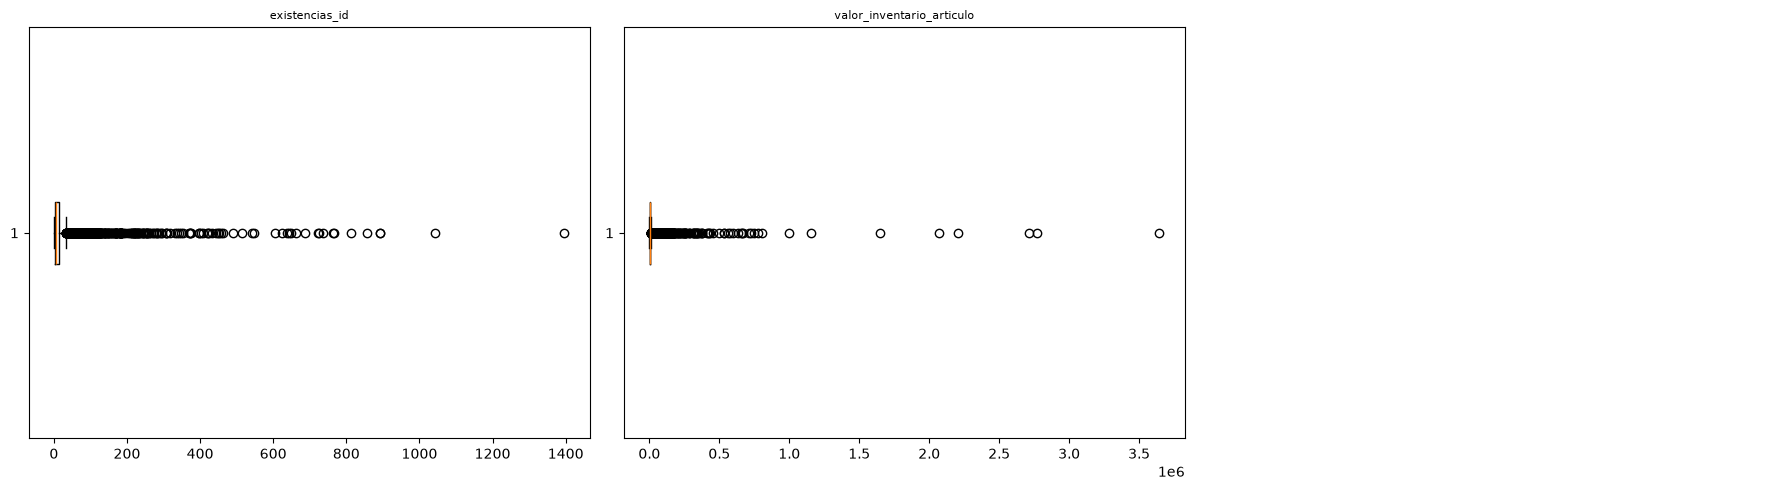

In [210]:
# Diagrama de caja por columna
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18,5))
axes = axes.flatten()
for i, col in enumerate(cuantitativas.columns):
    axes[i].boxplot(cuantitativas[col], vert=False)
    axes[i].set_title(col, fontsize=8)
for j in range(len(cuantitativas.columns), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

In [211]:
# Desviacion estandar: los atipicos se vuelven nulos solo en una copia
y = cuantitativas
Limite_Superior = y.mean() + 3*y.std()
Limite_Inferior = y.mean() - 3*y.std()
print('Limites inferiores STD:', Limite_Inferior)
print('Limites superiores STD:', Limite_Superior)
data_std = cuantitativas[(y <= Limite_Superior) & (y >= Limite_Inferior)]
data_std.isnull().sum()

Limites inferiores STD: existencias_id                 -218.592611
valor_inventario_articulo   -379787.309113
dtype: float64
Limites superiores STD: existencias_id                  273.763740
valor_inventario_articulo    425889.140126
dtype: float64


existencias_id               55
valor_inventario_articulo    25
dtype: int64

In [212]:
# Cuartiles IQR: parte de las mismas cuantitativas originales
percentile25 = y.quantile(0.25)
percentile75 = y.quantile(0.75)
iqr = percentile75 - percentile25
Limite_Superior_iqr = percentile75 + 1.5*iqr
Limite_Inferior_iqr = percentile25 - 1.5*iqr
print('Limites inferiores IQR:', Limite_Inferior_iqr)
print('Limites superiores IQR:', Limite_Superior_iqr)
data_iqr = cuantitativas[(y <= Limite_Superior_iqr) & (y >= Limite_Inferior_iqr)]
data_iqr.isnull().sum()

Limites inferiores IQR: existencias_id                -15.000
valor_inventario_articulo   -6638.285
dtype: float64
Limites superiores IQR: existencias_id                  33.000
valor_inventario_articulo    13872.555
dtype: float64


existencias_id               396
valor_inventario_articulo    471
dtype: int64

**Movimientos**

In [213]:
cuantitativas = movimientos_limpios[['SALIDAS_']]
cuantitativas.head()

,SALIDAS_
0,2
1,1
2,1
3,1
4,1


/var/folders/_k/8p4v02654tl0jtq5mfz55jqr0000gn/T/ipykernel_25742/3888548874.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(cuantitativas[col], vert=False)


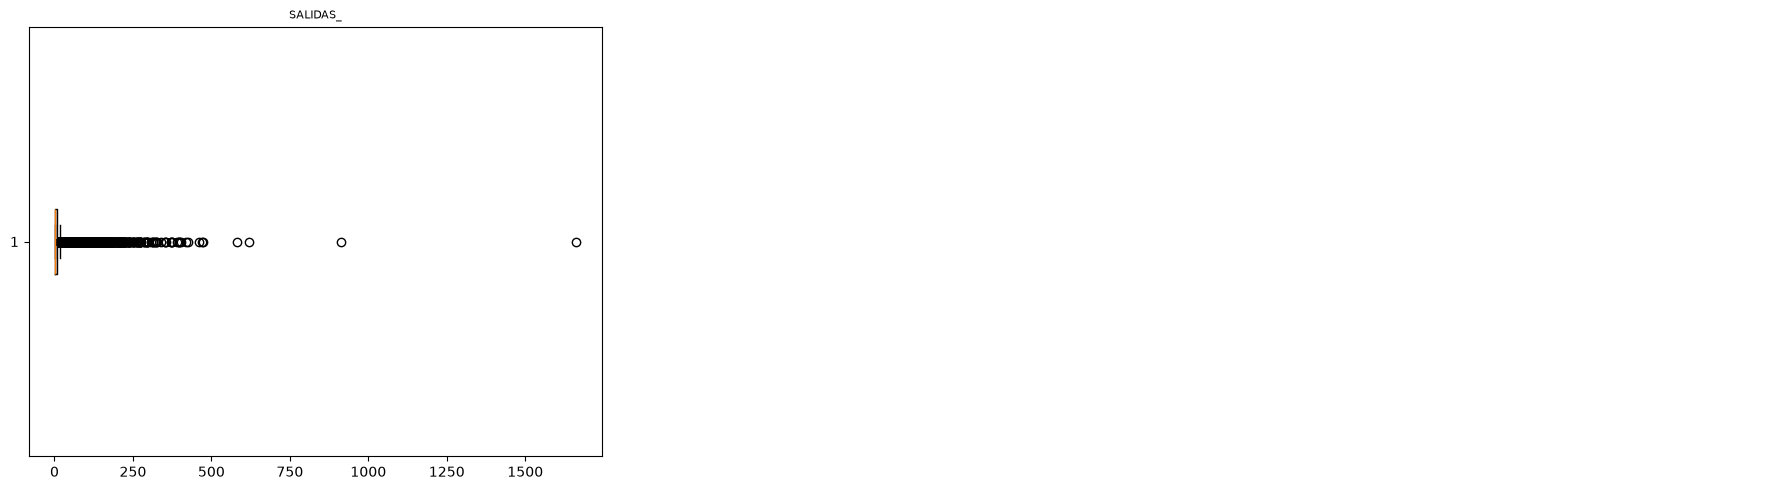

In [214]:
# Diagrama de caja por columna
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18,5))
axes = axes.flatten()
for i, col in enumerate(cuantitativas.columns):
    axes[i].boxplot(cuantitativas[col], vert=False)
    axes[i].set_title(col, fontsize=8)
for j in range(len(cuantitativas.columns), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

In [215]:
# Desviacion estandar: los atipicos se vuelven nulos solo en una copia
y = cuantitativas
Limite_Superior = y.mean() + 3*y.std()
Limite_Inferior = y.mean() - 3*y.std()
print('Limites inferiores STD:', Limite_Inferior)
print('Limites superiores STD:', Limite_Superior)
data_std = cuantitativas[(y <= Limite_Superior) & (y >= Limite_Inferior)]
data_std.isnull().sum()

Limites inferiores STD: SALIDAS_   -60.260393
dtype: float64
Limites superiores STD: SALIDAS_    79.638175
dtype: float64


SALIDAS_    994
dtype: int64

In [216]:
# Cuartiles IQR: parte de las mismas cuantitativas originales
percentile25 = y.quantile(0.25)
percentile75 = y.quantile(0.75)
iqr = percentile75 - percentile25
Limite_Superior_iqr = percentile75 + 1.5*iqr
Limite_Inferior_iqr = percentile25 - 1.5*iqr
print('Limites inferiores IQR:', Limite_Inferior_iqr)
print('Limites superiores IQR:', Limite_Superior_iqr)
data_iqr = cuantitativas[(y <= Limite_Superior_iqr) & (y >= Limite_Inferior_iqr)]
data_iqr.isnull().sum()

Limites inferiores IQR: SALIDAS_   -9.5
dtype: float64
Limites superiores IQR: SALIDAS_    18.5
dtype: float64


SALIDAS_    7118
dtype: int64

**Ventas**

In [217]:
cuantitativas = ventas_limpias[['precio_unitari_o', 'total_unidades_de_producto', 'total_neto_deproducto']]
cuantitativas.head()

,precio_unitari_o,total_unidades_de_producto,total_neto_deproducto
0,1310.35000,1,1310.35
1,508.62069,1,508.62
2,508.62069,1,508.62
3,508.62069,1,508.62
4,508.62069,1,508.62


/var/folders/_k/8p4v02654tl0jtq5mfz55jqr0000gn/T/ipykernel_25742/3888548874.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(cuantitativas[col], vert=False)
/var/folders/_k/8p4v02654tl0jtq5mfz55jqr0000gn/T/ipykernel_25742/3888548874.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(cuantitativas[col], vert=False)
/var/folders/_k/8p4v02654tl0jtq5mfz55jqr0000gn/T/ipykernel_25742/3888548874.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(cuantitativas[col], vert=False)


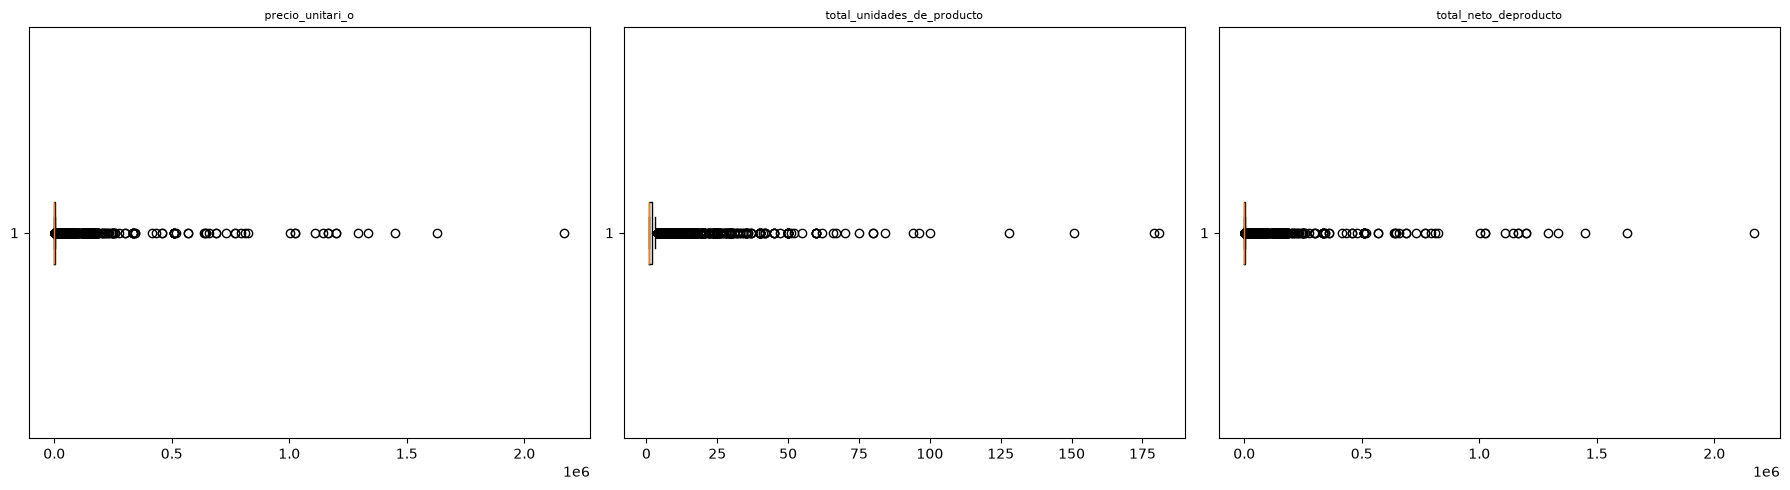

In [218]:
# Diagrama de caja por columna
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18,5))
axes = axes.flatten()
for i, col in enumerate(cuantitativas.columns):
    axes[i].boxplot(cuantitativas[col], vert=False)
    axes[i].set_title(col, fontsize=8)
for j in range(len(cuantitativas.columns), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

In [219]:
# Desviacion estandar: los atipicos se vuelven nulos solo en una copia
y = cuantitativas
Limite_Superior = y.mean() + 3*y.std()
Limite_Inferior = y.mean() - 3*y.std()
print('Limites inferiores STD:', Limite_Inferior)
print('Limites superiores STD:', Limite_Superior)
data_std = cuantitativas[(y <= Limite_Superior) & (y >= Limite_Inferior)]
data_std.isnull().sum()

Limites inferiores STD: precio_unitari_o             -124176.738588
total_unidades_de_producto       -13.036359
total_neto_deproducto        -124123.612845
dtype: float64
Limites superiores STD: precio_unitari_o              132851.962199
total_unidades_de_producto        18.622250
total_neto_deproducto         134900.889372
dtype: float64


precio_unitari_o              147
total_unidades_de_producto    445
total_neto_deproducto         149
dtype: int64

In [220]:
# Cuartiles IQR: parte de las mismas cuantitativas originales
percentile25 = y.quantile(0.25)
percentile75 = y.quantile(0.75)
iqr = percentile75 - percentile25
Limite_Superior_iqr = percentile75 + 1.5*iqr
Limite_Inferior_iqr = percentile25 - 1.5*iqr
print('Limites inferiores IQR:', Limite_Inferior_iqr)
print('Limites superiores IQR:', Limite_Superior_iqr)
data_iqr = cuantitativas[(y <= Limite_Superior_iqr) & (y >= Limite_Inferior_iqr)]
data_iqr.isnull().sum()

Limites inferiores IQR: precio_unitari_o             -1495.685518
total_unidades_de_producto      -0.500000
total_neto_deproducto        -2722.746250
dtype: float64
Limites superiores IQR: precio_unitari_o              2952.579311
total_unidades_de_producto       3.500000
total_neto_deproducto         5071.243750
dtype: float64


precio_unitari_o              1076
total_unidades_de_producto    3659
total_neto_deproducto         2150
dtype: int64

## 3. Transformaciones
Se utiliza pd.cut como en los ejemplos. La respuesta logistica sera 0 = una unidad y 1 = mas de una unidad. Se agrega una categoria de marca: VITA = 1 y otra marca = 0. Es una comparacion de una marca presente en la base, no una afirmacion de que sea mejor. Se conservan las columnas originales. pero No es necesario convertir todas las variables en dicotomicas.

In [221]:
# Comprobamos los valores de cantidad y marcas
print('Cantidad minima:', ventas_limpias['total_unidades_de_producto'].min())
print('Cantidad maxima:', ventas_limpias['total_unidades_de_producto'].max())
np.unique(ventas_limpias['marca_'])

Cantidad minima: 1
Cantidad maxima: 181


array(['AG', 'AIDITE', 'ANAX DENT', 'APPLE', 'ARMA DENTAL', 'ASIGA',
       'Actividad', 'CREATION', 'CYBERPUERTA', 'DURRD', 'Dekem', 'Denti',
       'EXOCAD', 'HUGE', 'IPD', 'JENSE', 'Komet', 'MEDIT', 'PHROZ',
       'QUATRO', 'RENFERT', 'ROKO', 'SCHIC', 'Shining 3D', 'VITA'],
      dtype=object)

In [222]:
# Creamos dos clases: una unidad y mas de una
# La base contiene cantidades enteras positivas; el minimo comprobado es 1
Max = ventas_limpias['total_unidades_de_producto'].max()
intervalos = [0, 1, Max]
categorias = [0, 1]
ventas_limpias['venta_multiple'] = pd.cut(x=ventas_limpias['total_unidades_de_producto'], bins=intervalos, labels=categorias)
ventas_limpias['venta_multiple'].value_counts()

venta_multiple
0    13086
1     8546
Name: count, dtype: int64

In [223]:
# Reemplazo de categorias con replace, como en el ejemplo logistico
ventas_limpias['marca_vita'] = ventas_limpias['marca_'].replace(
    ['AG', 'AIDITE', 'ANAX DENT', 'APPLE', 'ARMA DENTAL', 'ASIGA', 'Actividad', 'CREATION', 'CYBERPUERTA', 'DURRD', 'Dekem', 'Denti', 'EXOCAD', 'HUGE', 'IPD', 'JENSE', 'Komet', 'MEDIT', 'PHROZ', 'QUATRO', 'RENFERT', 'ROKO', 'SCHIC', 'Shining 3D'], 0)
ventas_limpias['marca_vita'] = ventas_limpias['marca_vita'].replace('VITA', 1)
np.unique(ventas_limpias['marca_vita'])

array([0, 1], dtype=object)

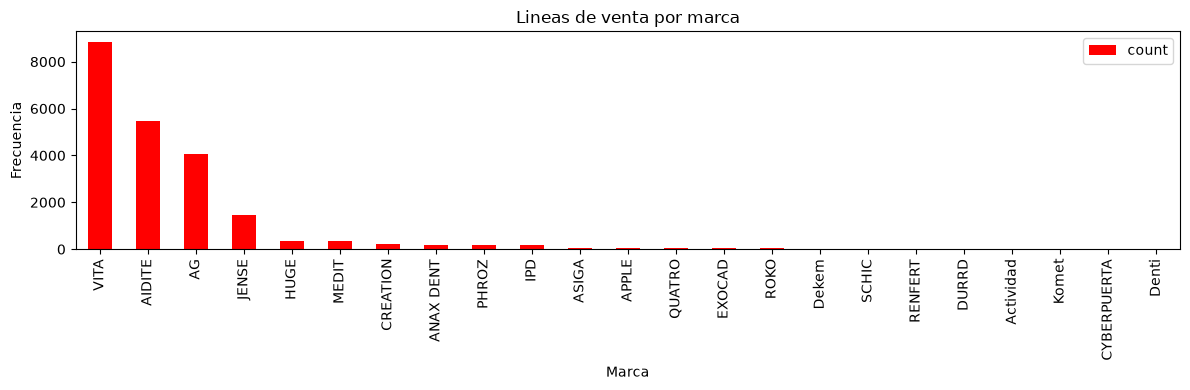

In [224]:
# Tabla de frecuencias y grafico, siguiendo extraccion de caracteristicas
Tabla_freq = ventas_limpias['marca_'].value_counts().reset_index()
Filtro = Tabla_freq[Tabla_freq['count'] > 1]
Filtro_index = Filtro.set_index('marca_')
Filtro_index.plot(kind='bar', figsize=(12,4), color='red')
plt.title('Lineas de venta por marca')
plt.xlabel('Marca')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

## 4. Regresion lineal simple
La mayor correlacion absoluta observada es precio unitario con importe neto, aproximadamente 0.993 en ventas.



In [225]:
# Correlaciones del inventario
Corr_inventario = inventario_limpio[['existencias_id','valor_inventario_articulo']].corr()
Corr_inventario

,existencias_id,valor_inventario_articulo
existencias_id,1.000000,0.188426
valor_inventario_articulo,0.188426,1.000000


In [226]:
# Correlaciones de ventas, sin identificadores
numericas = ventas_limpias[['precio_unitari_o', 'total_unidades_de_producto', 'total_neto_deproducto']]
Corr_Factors = numericas.corr()
Corr_Factors

,precio_unitari_o,total_unidades_de_producto,total_neto_deproducto
precio_unitari_o,1.000000,-0.029833,0.992679
total_unidades_de_producto,-0.029833,1.000000,0.009578
total_neto_deproducto,0.992679,0.009578,1.000000


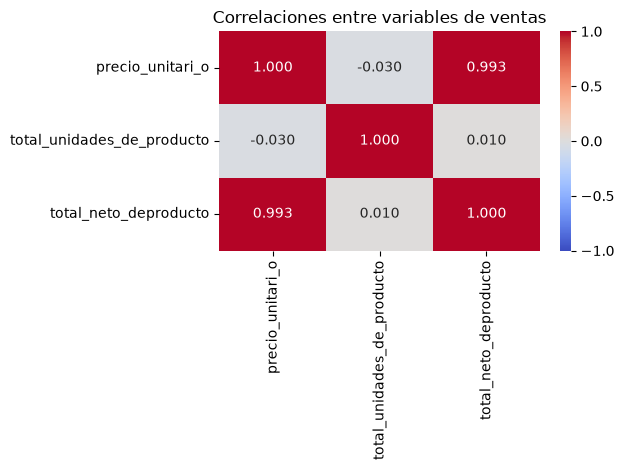

In [227]:
# Heatmap de correlaciones con signo
sns.heatmap(Corr_Factors, cmap='coolwarm', annot=True, fmt='.3f', vmin=-1, vmax=1)
plt.title('Correlaciones entre variables de ventas')
plt.tight_layout()
plt.show()

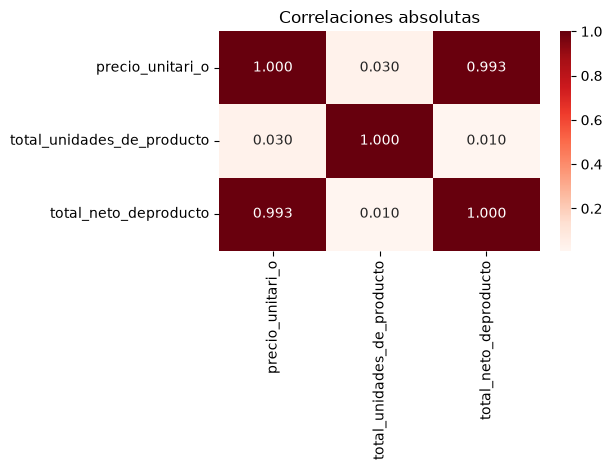

In [228]:
# Valor absoluto como en el ejemplo
Corr_Factors1 = abs(Corr_Factors)
sns.heatmap(Corr_Factors1, cmap='Reds', annot=True, fmt='.3f')
plt.title('Correlaciones absolutas')
plt.tight_layout()
plt.show()

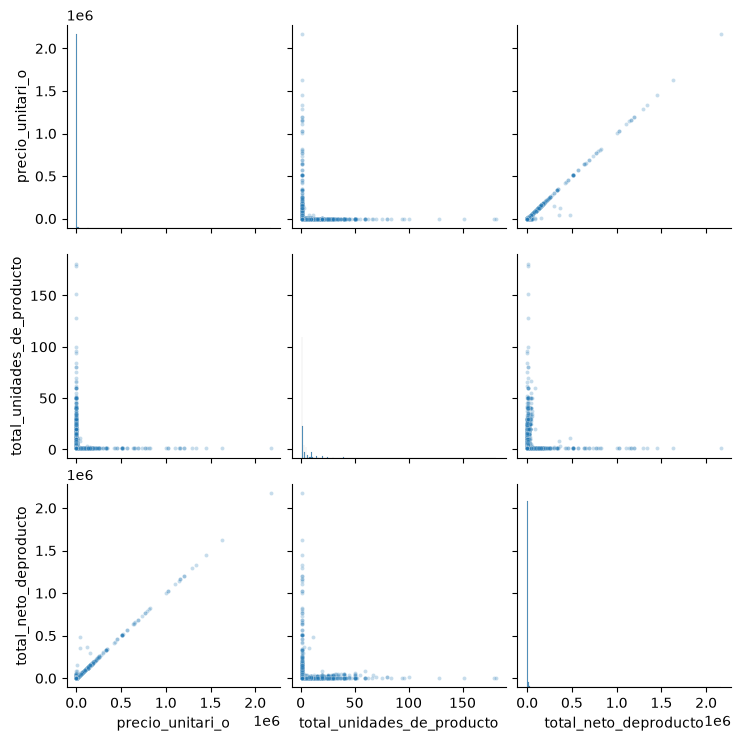

In [229]:
# Todas las dispersiones de las magnitudes
sns.pairplot(numericas, plot_kws={'s': 8, 'alpha': 0.25})
plt.show()

se utiliza train_test_split del ejemplo logistico tambien en las regresiones lineales. Se fija random_state para reproducibilidad. Se separa 30% para prueba; del 70% restante se reserva 20% para validacion. Los candidatos multiples se comparan solo en validacion.

El corte es aleatorio por linea, como el esquema de clase: distintas lineas de una factura pueden aparecer en conjuntos diferentes. Las metricas son orientativas sobre estas transacciones; no representan validacion por factura ni pronostico temporal. Se requeriria otra separacion para esos usos.

In [230]:
# Mismos conjuntos para comparar todos los modelos lineales
base_lineal, prueba = train_test_split(ventas_limpias, test_size=0.3, random_state=42)
entrenamiento, validacion = train_test_split(base_lineal, test_size=0.2, random_state=42)
print('Entrenamiento:', len(entrenamiento))
print('Validacion:', len(validacion))
print('Prueba:', len(prueba))

Entrenamiento: 12113
Validacion: 3029
Prueba: 6490


In [231]:
# Declaramos variables del modelo simple
Vars_Indep = entrenamiento[['precio_unitari_o']]
Var_Dep = entrenamiento['total_neto_deproducto']
model_simple = LinearRegression()
model_simple.fit(X=Vars_Indep, y=Var_Dep)
model_simple.__dict__

{'fit_intercept': True,
 'copy_X': True,
 'tol': 1e-06,
 'n_jobs': None,
 'positive': False,
 'feature_names_in_': array(['precio_unitari_o'], dtype=object),
 'n_features_in_': 1,
 'coef_': array([1.00037513]),
 'rank_': np.int64(1),
 'singular_': array([5431377.39041462]),
 'intercept_': np.float64(1071.8803987438941)}

In [232]:
# Modelo matematico y R2
print('Ecuacion: importe =', model_simple.coef_[0], '* precio +', model_simple.intercept_)
print('R2 entrenamiento:', model_simple.score(Vars_Indep, Var_Dep))
print('R2 validacion:', model_simple.score(validacion[['precio_unitari_o']], validacion['total_neto_deproducto']))
print('Correlacion con signo:')
Corr_Factors

Ecuacion: importe = 1.0003751262473077 * precio + 1071.8803987438941
R2 entrenamiento: 0.9853265150270588
R2 validacion: 0.9672932962047064
Correlacion con signo:


,precio_unitari_o,total_unidades_de_producto,total_neto_deproducto
precio_unitari_o,1.000000,-0.029833,0.992679
total_unidades_de_producto,-0.029833,1.000000,0.009578
total_neto_deproducto,0.992679,0.009578,1.000000


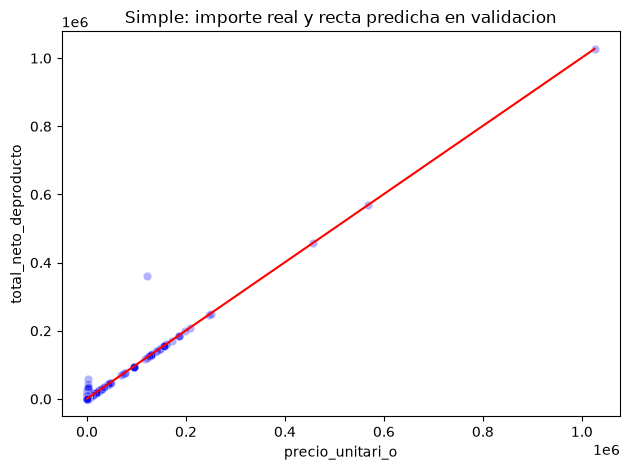

In [233]:
# Predicciones de validacion para la grafica comparativa
validacion_simple = validacion.copy()
y_pred = model_simple.predict(X=validacion[['precio_unitari_o']])
validacion_simple.insert(0, 'Predicciones', y_pred)
sns.scatterplot(x='precio_unitari_o', y='total_neto_deproducto', color='blue', data=validacion_simple, alpha=0.3)
sns.lineplot(x='precio_unitari_o', y='Predicciones', color='red', data=validacion_simple)
plt.title('Simple: importe real y recta predicha en validacion')
plt.tight_layout()
plt.show()

## 5. Regresion lineal multiple
Se mantiene la misma Y y se comparan dos candidatos: A = precio y cantidad; B = precio, cantidad y marca dicotomica. El mejor es el de mayor R² de validacion entre estos candidatos. No se afirma que sea el mejor modelo posible. Se excluye el producto precio × cantidad porque reconstruiria directamente el importe.

Marca se interpreta respecto a otras marcas. Los coeficientes multiples representan asociaciones manteniendo constantes las demas variables; su magnitud no mide importancia si las escalas difieren.

In [234]:
# Candidato A
Vars_Indep_A = entrenamiento[['precio_unitari_o', 'total_unidades_de_producto']]
Var_Dep = entrenamiento['total_neto_deproducto']
model_A = LinearRegression()
model_A.fit(X=Vars_Indep_A, y=Var_Dep)
model_A.__dict__

{'fit_intercept': True,
 'copy_X': True,
 'tol': 1e-06,
 'n_jobs': None,
 'positive': False,
 'feature_names_in_': array(['precio_unitari_o', 'total_unidades_de_producto'], dtype=object),
 'n_features_in_': 2,
 'coef_': array([  1.00151403, 387.42416873]),
 'rank_': np.int64(2),
 'singular_': array([5.43137739e+06, 5.34987137e+02]),
 'intercept_': np.float64(-1.0781174155836197)}

In [235]:
# Candidato B
Vars_Indep_B = entrenamiento[['precio_unitari_o', 'total_unidades_de_producto', 'marca_vita']]
model_B = LinearRegression()
model_B.fit(X=Vars_Indep_B, y=Var_Dep)
model_B.__dict__

{'fit_intercept': True,
 'copy_X': True,
 'tol': 1e-06,
 'n_jobs': None,
 'positive': False,
 'feature_names_in_': array(['precio_unitari_o', 'total_unidades_de_producto', 'marca_vita'],
       dtype=object),
 'n_features_in_': 3,
 'coef_': array([ 1.00068220e+00,  3.85346522e+02, -1.28215905e+03]),
 'rank_': np.int64(3),
 'singular_': array([5.43137739e+06, 5.34987847e+02, 5.40232935e+01]),
 'intercept_': np.float64(535.0351908719804)}

In [236]:
# Comparacion antes de utilizar prueba
r2_A = model_A.score(validacion[['precio_unitari_o', 'total_unidades_de_producto']], validacion['total_neto_deproducto'])
r2_B = model_B.score(validacion[['precio_unitari_o', 'total_unidades_de_producto', 'marca_vita']], validacion['total_neto_deproducto'])
print('R2 validacion A:', r2_A)
print('R2 validacion B:', r2_B)
# Elegimos A en caso de empate, por tener menos predictores
model_multiple = model_A
columnas_multiple = ['precio_unitari_o', 'total_unidades_de_producto']
nombre_multiple = 'A'
if r2_B > r2_A:
    model_multiple = model_B
    columnas_multiple = ['precio_unitari_o', 'total_unidades_de_producto', 'marca_vita']
    nombre_multiple = 'B'
print('Mejor candidato:', nombre_multiple)

R2 validacion A: 0.9705801870893231
R2 validacion B: 0.971059989615233
Mejor candidato: B


In [237]:
# Coeficientes y ecuacion del modelo multiple seleccionado
print('Intercepto:', model_multiple.intercept_)
for i, col in enumerate(columnas_multiple):
    print('Coeficiente de', col, ':', model_multiple.coef_[i])
print('Ecuacion: importe =', model_multiple.intercept_, '+', model_multiple.coef_[0], '* precio +', model_multiple.coef_[1], '* cantidad')
if len(columnas_multiple) == 3:
    print('Agregar a la ecuacion:', model_multiple.coef_[2], '* marca_vita')
print('Coeficiente precio simple:', model_simple.coef_[0])
print('Coeficiente precio multiple:', model_multiple.coef_[0])
print('El precio multiple se interpreta controlando cantidad y, si aplica, marca.')

Intercepto: 535.0351908719804
Coeficiente de precio_unitari_o : 1.0006822017832813
Coeficiente de total_unidades_de_producto : 385.3465221163403
Coeficiente de marca_vita : -1282.159054282873
Ecuacion: importe = 535.0351908719804 + 1.0006822017832813 * precio + 385.3465221163403 * cantidad
Agregar a la ecuacion: -1282.159054282873 * marca_vita
Coeficiente precio simple: 1.0003751262473077
Coeficiente precio multiple: 1.0006822017832813
El precio multiple se interpreta controlando cantidad y, si aplica, marca.


In [238]:
# Evaluacion final, sin volver a escoger usando la prueba
pred_simple = model_simple.predict(X=prueba[['precio_unitari_o']])
pred_multiple = model_multiple.predict(X=prueba[columnas_multiple])
print('R2 simple en prueba:', model_simple.score(prueba[['precio_unitari_o']], prueba['total_neto_deproducto']))
print('R2 multiple en prueba:', model_multiple.score(prueba[columnas_multiple], prueba['total_neto_deproducto']))
# MAE y RMSE mediante operaciones y mean del ejemplo de preprocesamiento
error_simple = prueba['total_neto_deproducto'] - pred_simple
error_multiple = prueba['total_neto_deproducto'] - pred_multiple
print('MAE simple:', abs(error_simple).mean())
print('MAE multiple:', abs(error_multiple).mean())
print('RMSE simple:', np.sqrt((error_simple**2).mean()))
print('RMSE multiple:', np.sqrt((error_multiple**2).mean()))
print('Predicciones negativas simple:', (pred_simple < 0).sum())
print('Predicciones negativas multiple:', (pred_multiple < 0).sum())

R2 simple en prueba: 0.9917116877165982
R2 multiple en prueba: 0.9929702011333152
MAE simple: 1457.066008437856
MAE multiple: 1154.39347303558
RMSE simple: 3152.007559643701
RMSE multiple: 2902.857033005075
Predicciones negativas simple: 0
Predicciones negativas multiple: 1359


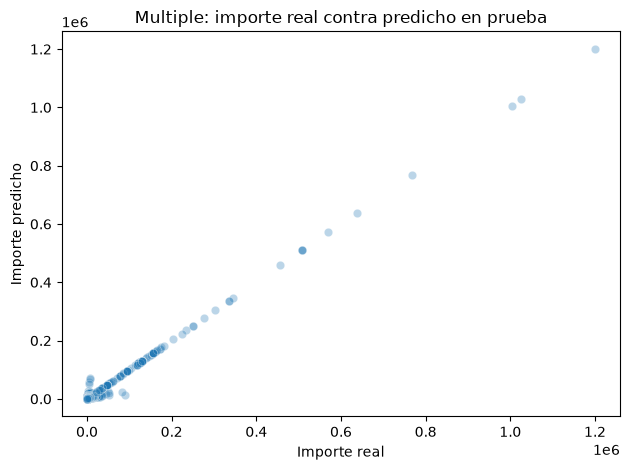

In [239]:
# Grafico de real contra predicho del multiple
prueba_grafica = prueba.copy()
prueba_grafica.insert(0, 'Predicciones', pred_multiple)
sns.scatterplot(x='total_neto_deproducto', y='Predicciones', data=prueba_grafica, alpha=0.3)
plt.title('Multiple: importe real contra predicho en prueba')
plt.xlabel('Importe real')
plt.ylabel('Importe predicho')
plt.tight_layout()
plt.show()

## 6 y 7. Regresion logistica, reponderacion y dicotomicas
**Y:** venta_multiple, con 0 = una unidad y 1 = mas de una. **X:** precio unitario y marca_vita. Se excluye cantidad porque define Y y tambien el importe neto porque incorpora informacion sobre ella.

Se retoma el flujo del profe: separar conjuntos, escalar con entrenamiento, ajustar LogisticRegression, predecir y calcular matriz de confusion, precision, exactitud, sensibilidad y F1. Se usa la misma clase positiva (1) en todas las metricas, corrigiendo la inconsistencia de etiquetas del ejemplo.

Se agrega el argumento class_weight="balanced" para cumplir la reponderacion solicitada. No es un algoritmo adicional: da mayor peso a la clase menos frecuente. Se compara con el ajuste sin pesos. No se repondera ni remuestrea la prueba. El split es estratificado para mantener ambas clases representadas.

In [240]:
# Frecuencias antes del ajuste
ventas_limpias['venta_multiple'].value_counts()

venta_multiple
0    13086
1     8546
Name: count, dtype: int64

In [241]:
# Variables de la logistica
Vars_Indep = ventas_limpias[['precio_unitari_o', 'marca_vita']]
Var_Dep = ventas_limpias['venta_multiple']
X = Vars_Indep
y = Var_Dep
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print('Clases en entrenamiento:')
print(y_train.value_counts())
print('Clases en prueba:')
print(y_test.value_counts())

Clases en entrenamiento:
venta_multiple
0    9160
1    5982
Name: count, dtype: int64
Clases en prueba:
venta_multiple
0    3926
1    2564
Name: count, dtype: int64


In [242]:
# Escalamos como en el ejemplo; la prueba no se usa para ajustar el escalador
escalar = StandardScaler()
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

In [243]:
# Comparacion sin reponderacion
algoritmo_base = LogisticRegression(max_iter=2000)
algoritmo_base.fit(X_train, y_train)
y_pred_base = algoritmo_base.predict(X_test)
print('Matriz sin pesos:')
print(confusion_matrix(y_test, y_pred_base))
print('Precision:', precision_score(y_test, y_pred_base, average='binary', pos_label=1, zero_division=0))
print('Exactitud:', accuracy_score(y_test, y_pred_base))
print('Sensibilidad:', recall_score(y_test, y_pred_base, average='binary', pos_label=1, zero_division=0))
print('F1:', f1_score(y_test, y_pred_base, average='binary', pos_label=1, zero_division=0))

Matriz sin pesos:
[[3926    0]
 [2564    0]]
Precision: 0.0
Exactitud: 0.6049306625577812
Sensibilidad: 0.0
F1: 0.0


In [244]:
# Modelo solicitado: reponderacion automatica de clases
algoritmo = LogisticRegression(class_weight='balanced', max_iter=2000)
algoritmo.fit(X_train, y_train)
y_pred = algoritmo.predict(X_test)
algoritmo.__dict__

{'penalty': 'deprecated',
 'C': 1.0,
 'l1_ratio': 0.0,
 'dual': False,
 'tol': 0.0001,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'class_weight': 'balanced',
 'random_state': None,
 'solver': 'lbfgs',
 'max_iter': 2000,
 'verbose': 0,
 'warm_start': False,
 'n_jobs': None,
 'n_features_in_': 2,
 'classes_': array([0, 1]),
 'n_iter_': array([10], dtype=int32),
 'coef_': array([[-4.36835189, -0.24101544]]),
 'intercept_': array([-0.32552653])}

Filas = clase real; columnas = clase predicha; orden 0, 1
[[2021 1905]
 [ 953 1611]]


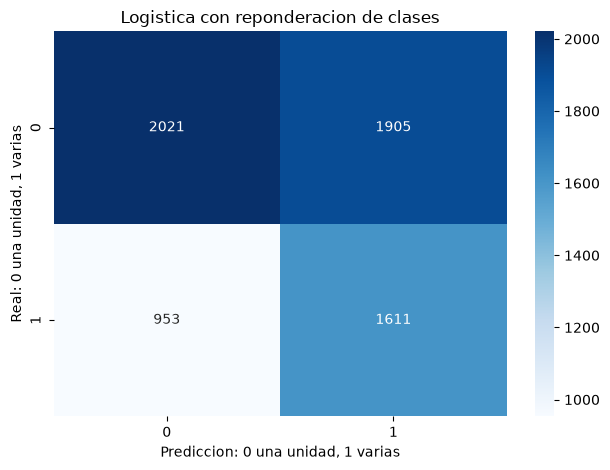

In [245]:
# Matriz de confusion de la logistica reponderada
matriz = confusion_matrix(y_test, y_pred)
print('Filas = clase real; columnas = clase predicha; orden 0, 1')
print(matriz)
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prediccion: 0 una unidad, 1 varias')
plt.ylabel('Real: 0 una unidad, 1 varias')
plt.title('Logistica con reponderacion de clases')
plt.tight_layout()
plt.show()

In [246]:
# Usamos la clase positiva 1 en todas las metricas
precision = precision_score(y_test, y_pred, average='binary', pos_label=1, zero_division=0)
exactitud = accuracy_score(y_test, y_pred)
sensibilidad = recall_score(y_test, y_pred, average='binary', pos_label=1, zero_division=0)
puntajef1 = f1_score(y_test, y_pred, average='binary', pos_label=1, zero_division=0)
print('Precision:', precision)
print('Exactitud:', exactitud)
print('Sensibilidad:', sensibilidad)
print('F1:', puntajef1)

Precision: 0.45819112627986347
Exactitud: 0.5596302003081665
Sensibilidad: 0.6283151326053042
F1: 0.5299342105263158


In [247]:
# Coeficientes y ecuacion de la logistica
print('Intercepto:', algoritmo.intercept_[0])
print('Coeficiente precio escalado:', algoritmo.coef_[0][0])
print('Coeficiente marca_vita escalada:', algoritmo.coef_[0][1])
print('z =', algoritmo.intercept_[0], '+', algoritmo.coef_[0][0], '* precio_escalado +', algoritmo.coef_[0][1], '* marca_escalada')
print('p(venta_multiple=1) = 1 / (1 + exp(-z))')
print('Escalamiento: x_escalada = (x - media_entrenamiento) / escala_entrenamiento')
# Parametros del escalador para poder reconstruir la ecuacion
escalar.__dict__

Intercepto: -0.32552652807529175
Coeficiente precio escalado: -4.3683518890163215
Coeficiente marca_vita escalada: -0.24101543908812245
z = -0.32552652807529175 + -4.3683518890163215 * precio_escalado + -0.24101543908812245 * marca_escalada
p(venta_multiple=1) = 1 / (1 + exp(-z))
Escalamiento: x_escalada = (x - media_entrenamiento) / escala_entrenamiento


{'with_mean': True,
 'with_std': True,
 'copy': True,
 'feature_names_in_': array(['precio_unitari_o', 'marca_vita'], dtype=object),
 'n_features_in_': 2,
 'n_samples_seen_': np.float64(15142.0),
 'mean_': array([4.34848388e+03, 4.07277770e-01]),
 'var_': array([1.83415222e+09, 2.41402588e-01]),
 'scale_': array([4.28270034e+04, 4.91327374e-01])}

## Resultados 

- Simple: R² de prueba = 0.9917; MAE = 1457.07; RMSE = 3152.01.
- Multiple: se selecciono B (precio, cantidad y marca VITA), por R² de validacion 0.9711 frente a 0.9706 del candidato A. En prueba: R² = 0.9930; MAE = 1154.39; RMSE = 2902.86.
- Aunque el multiple reduce el error promedio, produce 1359 predicciones negativas de 6490 lineas de prueba. Es una limitacion importante: no se recomienda usarlo operativamente como estimador de importes sin corregir el enfoque y validar de nuevo. El modelo simple no produce negativas en esta prueba.
- Logistica sin pesos: exactitud 0.6049, pero sensibilidad 0 para compras de varias unidades: siempre predice una unidad.
- Logistica reponderada: precision 0.4582, exactitud 0.5596, sensibilidad 0.6283 y F1 0.5299. Detecta parte de las compras de varias unidades, con falsos positivos importantes. No es un modelo de alta capacidad predictiva con estos dos predictores.

La alta correlacion contable y el alto R² lineal no eliminan estas limitaciones. Los resultados son un ejercicio academico exploratorio, no un modelo listo para decisiones comerciales.


## Interpretacion y alcance

regresion Lineal simple: la correlacion precio a importe es alta, en parte por la formula contable. La ecuacion es descriptiva, no causal. Un R² alto no significa automaticamente utilidad comercial.

**Multiple:** se agrega cantidad y se compara incluir la marca dicotomica. Se elige por validacion y se reporta la prueba sin cambiar la eleccion. Si no mejora en prueba, se debe decir. MAE expresa el error absoluto promedio y RMSE da mayor peso a errores grandes. Las predicciones negativas son una limitacion del ajuste lineal y se reportan sin ocultarlas.

**Logistica:** la reponderacion puede elevar sensibilidad y reducir precision o exactitud; no garantiza mejorar todos los indicadores. La ecuacion usa predictores estandarizados. Las probabilidades del modelo reponderado no deben interpretarse como frecuencias reales calibradas. El ajuste predice una linea de varias unidades, no compras futuras de un cliente.

Los resultados conservan valores extremos reales; no se aplica una sustitucion de outliers sin justificacion. La seleccion de la pareja mas correlacionada es exploratoria sobre la base completa. 
